# MTLoRA — M-product Tensor LoRA: Test & Analysis Notebook

This notebook covers three phases:

**Phase 1 – Decomposition benchmark on ΔW** 
Load pre-computed approximation-error-vs-parameters data for Tucker2 (LoTR), CP (LoRTA), t-SVD with DCT/random/identity and per-layer SVD.  Visualise Pareto curves and depth-structure diagnostics.

**Phase 2 – MTLoRA training** 
Run and compare MTLoRA variants (transform, n_faces, α, W₀-init) on CoLA with live face-energy monitoring and optional dynamic rank pruning.

**Phase 3 – Post-hoc analysis** 
Inspect the trained adapter: per-face singular value spectrum, learned ΔW subspace vs W₀, and parameter-efficiency versus performance table.

In [1]:
# ── dependencies ──────────────────────────────────────────────────────────────
import json, os, warnings
warnings.filterwarnings('ignore')

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D

# project modules
from mt_lora import MTLoRA, wrap_roberta_attention_fast
from tensor_utils.transformation_matrices import dct_matrix
from delta_w_compare import (
    make_M, face_svdvals, transform as dw_transform,
    depth_energy_spectrum, layer_subspace_overlap,
    run_tsvd_global, run_tucker, run_lora_layer, pareto, params_to_reach, fro2
)

%matplotlib inline
plt.rcParams.update({'figure.dpi': 130, 'axes.grid': True,
                     'grid.alpha': 0.3, 'font.size': 11})
print('torch:', torch.__version__,
      '  device:', 'mps' if torch.backends.mps.is_available() else
                  'cuda' if torch.cuda.is_available() else 'cpu')

torch: 2.14.1   device: mps


---
## Phase 1 — Decomposition benchmark on ΔW
### 1.1 Load pre-computed comparison data

In [2]:
CMP_DIR = 'results/cmp_cola'
DW_FILE = 'results/dw_cola_seed0.pt'

# Load per-projection results
cmp = {}
for proj in ('q', 'k', 'v', 'o'):
    path = os.path.join(CMP_DIR, f'{proj}.json')
    if os.path.exists(path):
        cmp[proj] = json.load(open(path))

# Load raw ΔW tensors
dw_blob = torch.load(DW_FILE, map_location='cpu')
print('Projections available:', list(cmp.keys()))
print('Meta:', dw_blob.get('meta'))
for k in ('q','k','v','o'):
    print(f'  ΔW_{k}: {tuple(dw_blob[k].shape)}')

Projections available: ['q', 'k', 'v', 'o']
Meta: {'task': 'cola', 'model': 'roberta-base', 'epochs': 3, 'lr': 2e-05, 'seed': 0, 'val_mcc': 0.570240121346637}
  ΔW_q: (768, 768, 12)
  ΔW_k: (768, 768, 12)
  ΔW_v: (768, 768, 12)
  ΔW_o: (768, 768, 12)


### 1.2 Pareto error-vs-parameters curves for all methods

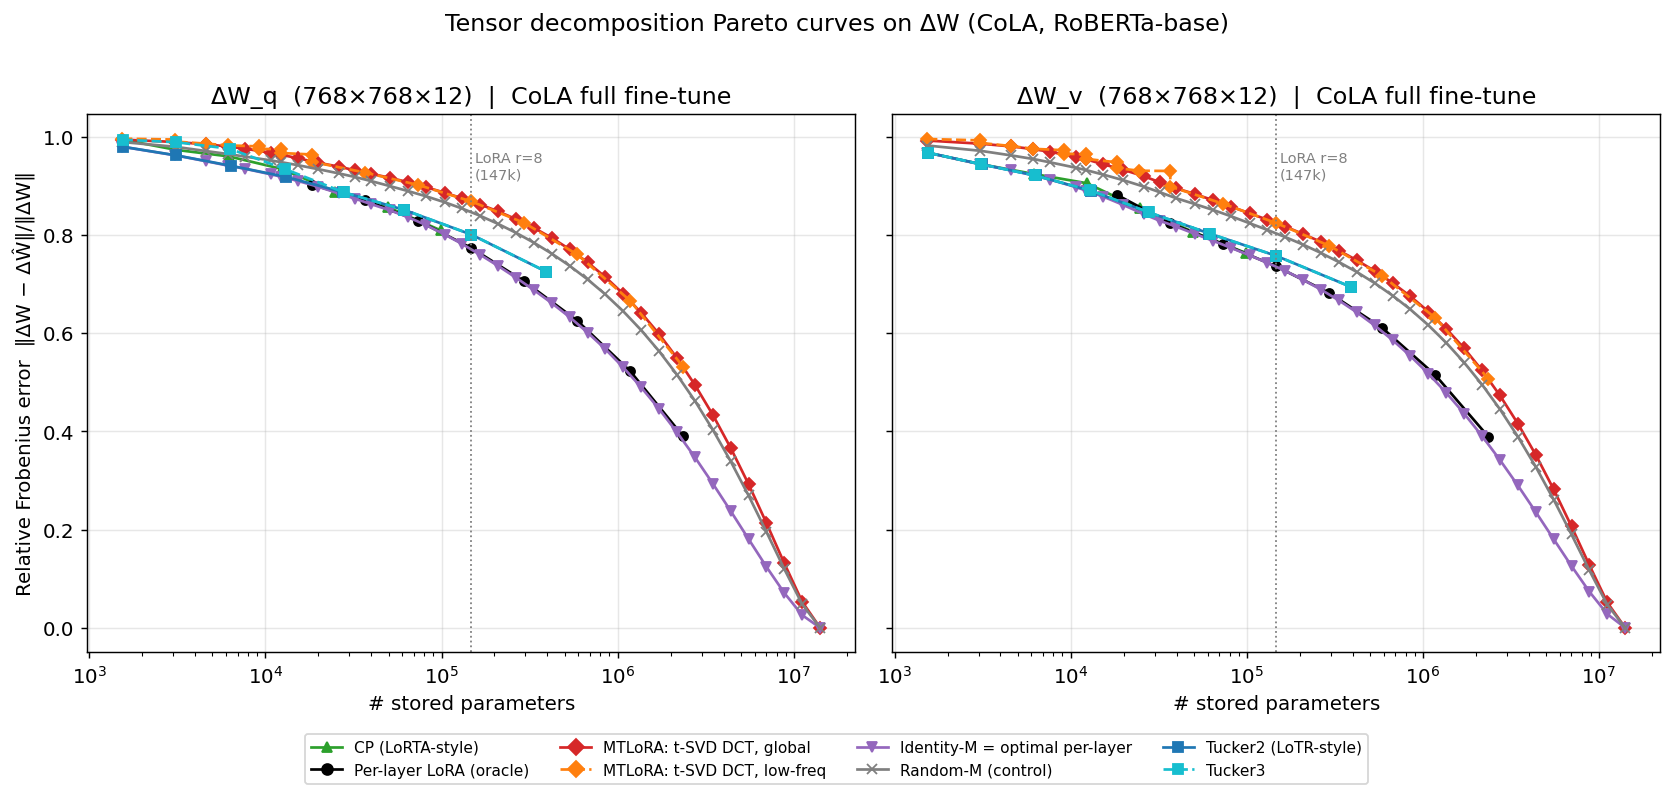

In [3]:
# ── Style map ─────────────────────────────────────────────────────────────────
STYLE = {
    'lora_layer':       ('black',         'o',  '-',  'Per-layer LoRA (oracle)'),
    'tucker2':          ('tab:blue',      's',  '-',  'Tucker2 (LoTR-style)'),
    'tucker3':          ('tab:cyan',      's',  '--', 'Tucker3'),
    'cp':               ('tab:green',     '^',  '-',  'CP (LoRTA-style)'),
    'tsvd_dct_global':  ('tab:red',       'D',  '-',  'MTLoRA: t-SVD DCT, global'),
    'tsvd_dct_lowfreq': ('tab:orange',    'D',  '--', 'MTLoRA: t-SVD DCT, low-freq'),
    'tsvd_rand_global': ('tab:gray',      'x',  '-',  'Random-M (control)'),
    'tsvd_id_global':   ('tab:purple',    'v',  '-',  'Identity-M = optimal per-layer'),
}

projs_to_show = ('q', 'v')   # most informative; q and v are the LoTR target projections

fig, axes = plt.subplots(1, len(projs_to_show), figsize=(6.5 * len(projs_to_show), 5.5),
                          sharey=True)
if len(projs_to_show) == 1:
    axes = [axes]

all_methods = sorted(STYLE)

for ax, proj in zip(axes, projs_to_show):
    data = cmp[proj]
    n1, n2, L = data['shape']
    lora_r8_params = L * 8 * (n1 + n2)

    for method in all_methods:
        pts = pareto([p for p in data['points'] if p['method'] == method])
        if not pts:
            continue
        c, mk, ls, _ = STYLE[method]
        ax.plot([d['params'] for d in pts],
                [d['rel_err'] for d in pts],
                color=c, marker=mk, linestyle=ls, ms=5, linewidth=1.5)

    ax.axvline(lora_r8_params, color='gray', linestyle=':', linewidth=1)
    ax.text(lora_r8_params * 1.05, 0.97, f'LoRA r=8\n({lora_r8_params//1000}k)',
            fontsize=8, va='top', color='gray')
    ax.set_xscale('log')
    ax.set_xlabel('# stored parameters')
    ax.set_title(f'ΔW_{proj}  ({n1}×{n2}×{L})  |  CoLA full fine-tune')

axes[0].set_ylabel('Relative Frobenius error  ‖ΔW − ΔŴ‖/‖ΔW‖')

legend_handles = [
    Line2D([0], [0], color=STYLE[m][0], marker=STYLE[m][1],
           linestyle=STYLE[m][2], ms=6, label=STYLE[m][3])
    for m in all_methods if m in STYLE
]
fig.legend(handles=legend_handles, loc='lower center',
           ncol=4, fontsize=8.5, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Tensor decomposition Pareto curves on ΔW (CoLA, RoBERTa-base)', y=1.01)
plt.tight_layout()
plt.savefig('results/pareto_curves.png', bbox_inches='tight', dpi=150)
plt.show()

### 1.3 Parameter table — minimum params to reach a target error threshold

In [4]:
THRESHOLDS = [0.9, 0.8, 0.7, 0.6]
METHODS_SHOW = ['tucker2', 'cp', 'tsvd_dct_global', 'tsvd_dct_lowfreq',
                'tsvd_rand_global', 'tsvd_id_global', 'lora_layer']

for proj in ('q', 'v', 'o'):
    data = cmp[proj]
    header = f"\n--- ΔW_{proj}  {data['shape']} ---\n"
    header += f"{'method':<24}" + "".join(f"{t:>12}" for t in THRESHOLDS)
    print(header)
    for m in METHODS_SHOW:
        pts = pareto([p for p in data['points'] if p['method'] == m])
        row = [params_to_reach(pts, t) for t in THRESHOLDS]
        print(f"{m:<24}" + "".join(f"{('-' if v is None else f'{v:,}'):>12}" for v in row))


--- ΔW_q  [768, 768, 12] ---
method                           0.9         0.8         0.7         0.6
tucker2                       27,648     393,216           -           -
cp                            24,768           -           -           -
tsvd_dct_global               81,408     422,400   1,078,272   1,721,856
tsvd_dct_lowfreq             147,456     589,824   1,179,648   2,359,296
tsvd_rand_global              50,688     334,848     852,480   1,721,856
tsvd_id_global                19,968     130,560     334,848     852,480
lora_layer                    36,864     147,456     589,824   1,179,648

--- ΔW_v  [768, 768, 12] ---
method                           0.9         0.8         0.7         0.6
tucker2                       13,056     147,456     393,216           -
cp                            24,768      99,072           -           -
tsvd_dct_global               39,936     264,192     852,480   1,721,856
tsvd_dct_lowfreq              36,864     294,912   1,179,648   2

### 1.4 Depth-structure diagnostics — energy spectrum and subspace alignment

ΔW_q — DCT energy top-3/12: 0.246  adj-layer subspace cos: 0.131  random baseline: 0.113
ΔW_k — DCT energy top-3/12: 0.243  adj-layer subspace cos: 0.128  random baseline: 0.113
ΔW_v — DCT energy top-3/12: 0.253  adj-layer subspace cos: 0.122  random baseline: 0.113
ΔW_o — DCT energy top-3/12: 0.253  adj-layer subspace cos: 0.430  random baseline: 0.113


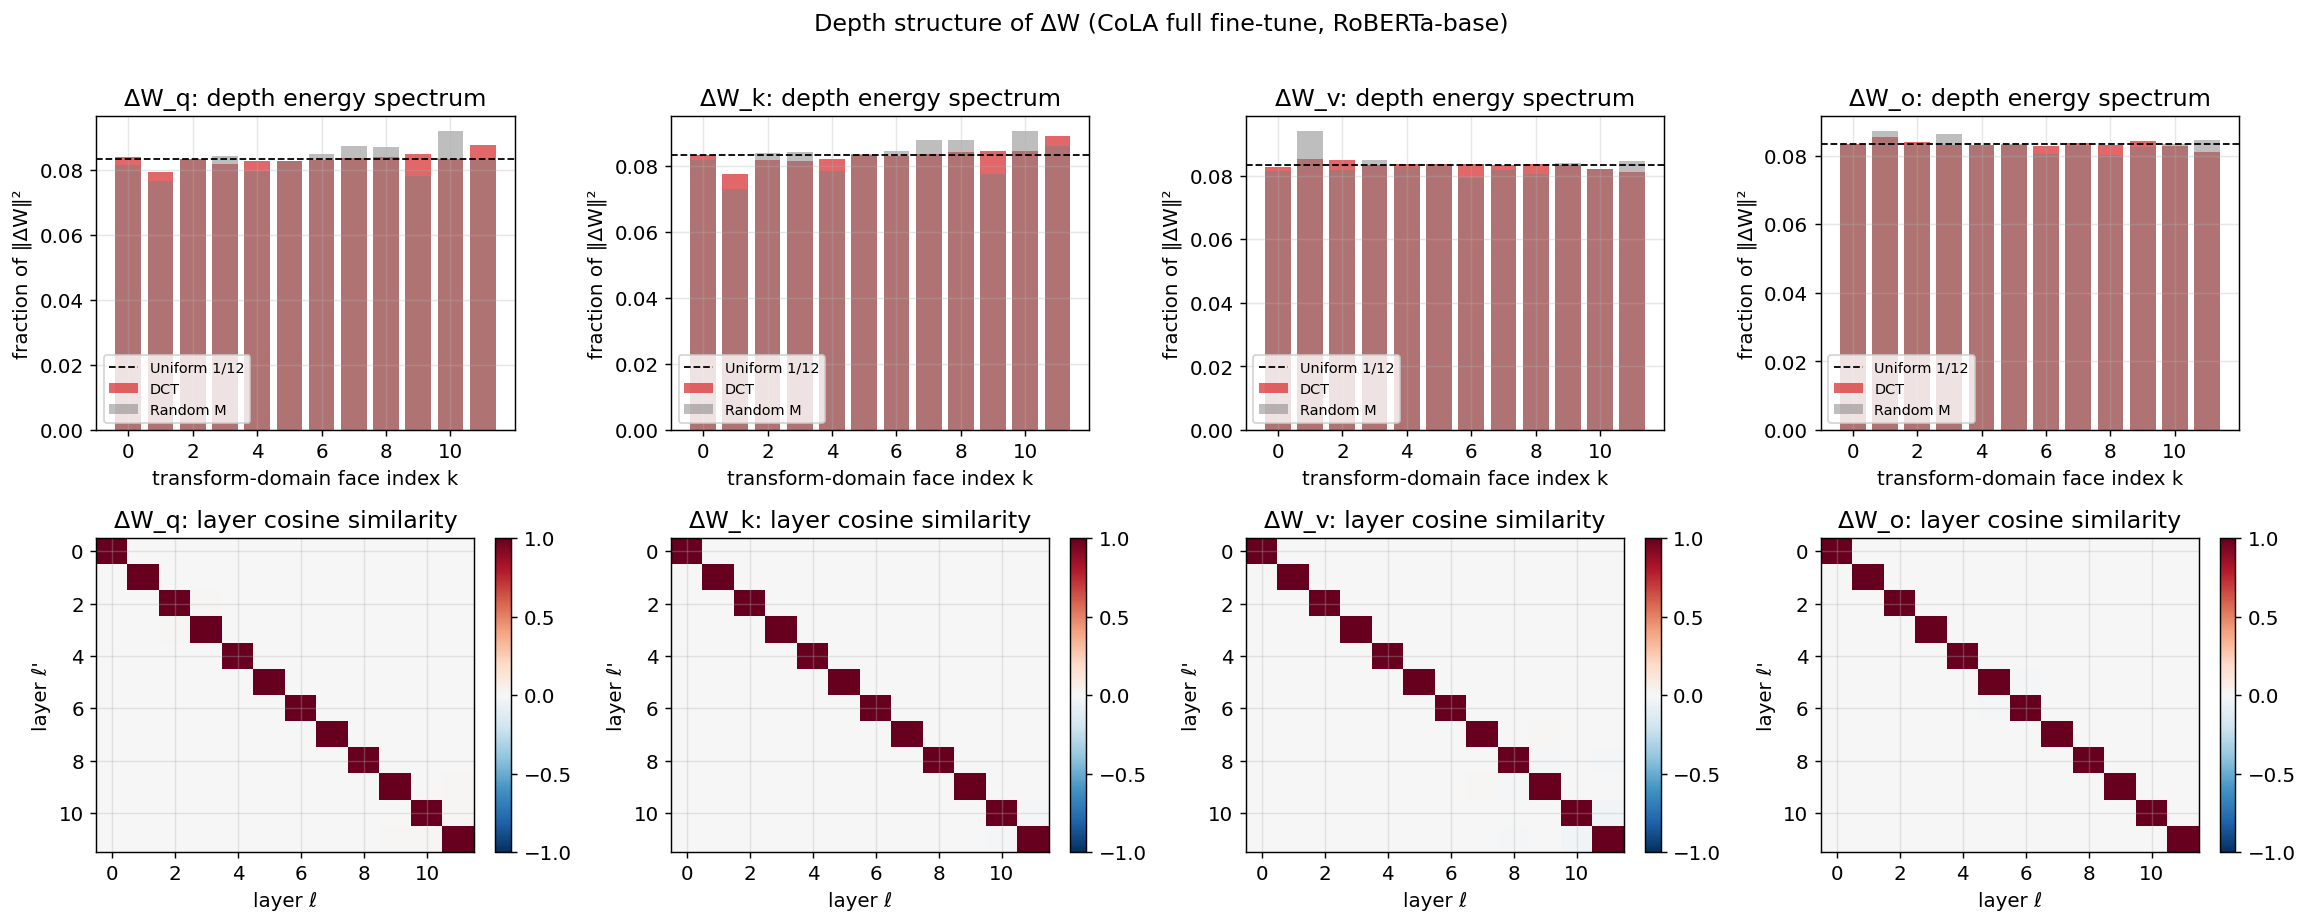

In [5]:
DT = torch.float64

fig, axes = plt.subplots(2, 4, figsize=(18, 7))
proj_list = ('q', 'k', 'v', 'o')

for col, proj in enumerate(proj_list):
    data = cmp[proj]
    L = data['shape'][2]

    # ── Energy spectrum ────────────────────────────────────────────────────────
    ax = axes[0, col]
    dct_spec  = data['depth_spectrum']['dct']
    rand_spec = data['depth_spectrum']['rand']
    ax.bar(range(L), dct_spec,  alpha=0.7, color='tab:red',  label='DCT')
    ax.bar(range(L), rand_spec, alpha=0.5, color='tab:gray', label='Random M')
    ax.axhline(1/L, color='k', linestyle='--', linewidth=1, label=f'Uniform 1/{L}')
    ax.set_title(f'ΔW_{proj}: depth energy spectrum')
    ax.set_xlabel('transform-domain face index k')
    ax.set_ylabel('fraction of ‖ΔW‖²')
    ax.legend(fontsize=8)

    # ── Subspace overlap heatmap ───────────────────────────────────────────────
    ax2 = axes[1, col]
    C   = np.array(data['layer_cosine'])
    im  = ax2.imshow(C, cmap='RdBu_r', vmin=-1, vmax=1, aspect='auto')
    ax2.set_title(f'ΔW_{proj}: layer cosine similarity')
    ax2.set_xlabel('layer ℓ'); ax2.set_ylabel('layer ℓ\'')
    plt.colorbar(im, ax=ax2, fraction=0.046)

    ov = data['subspace_overlap']
    adj = ov['left_by_distance'].get('1', float('nan'))
    print(f"ΔW_{proj} — DCT energy top-3/{L}: {sum(dct_spec[:3]):.3f}  "
          f"adj-layer subspace cos: {adj:.3f}  "
          f"random baseline: {ov['random_left']:.3f}")

fig.suptitle('Depth structure of ΔW (CoLA full fine-tune, RoBERTa-base)', y=1.01)
plt.tight_layout()
plt.savefig('results/depth_structure.png', bbox_inches='tight', dpi=150)
plt.show()

---
## Phase 2 — MTLoRA training
### 2.1 Setup

In [6]:
from datasets import load_dataset
from sklearn.metrics import matthews_corrcoef, accuracy_score
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          get_linear_schedule_with_warmup)

DEVICE = (torch.device('mps')  if torch.backends.mps.is_available()  else
          torch.device('cuda') if torch.cuda.is_available() else
          torch.device('cpu'))
print('Device:', DEVICE)

# ── Data helpers ──────────────────────────────────────────────────────────────
def make_loader(ds, tok, k1, k2, batch_size, shuffle, max_len=128):
    def encode(batch):
        args = (batch[k1],) if k2 is None else (batch[k1], batch[k2])
        return tok(*args, truncation=True, max_length=max_len)
    ds = ds.map(encode, batched=True)
    ds = ds.with_format('python', columns=['input_ids', 'attention_mask', 'label'])
    def collate(items):
        n   = max(len(x['input_ids']) for x in items)
        ids = torch.full((len(items), n), tok.pad_token_id, dtype=torch.long)
        att = torch.zeros((len(items), n), dtype=torch.long)
        for i, x in enumerate(items):
            L2 = len(x['input_ids']); ids[i,:L2] = torch.tensor(x['input_ids']); att[i,:L2] = 1
        return ids, att, torch.tensor([x['label'] for x in items], dtype=torch.long)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size,
                                       shuffle=shuffle, collate_fn=collate)

@torch.no_grad()
def evaluate(model, loader, metric):
    model.eval()
    preds, gold = [], []
    for ids, att, y in loader:
        logits = model(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE)).logits
        preds.extend(logits.argmax(-1).cpu().tolist()); gold.extend(y.tolist())
    return (matthews_corrcoef(gold, preds) if metric == 'mcc'
            else accuracy_score(gold, preds))

# ── Load CoLA once (shared across experiments) ─────────────────────────────────
TASK, K1, K2, METRIC = 'cola', 'sentence', None, 'mcc'
tok  = AutoTokenizer.from_pretrained('roberta-base')
raw  = load_dataset('nyu-mll/glue', TASK)
train_dl = make_loader(raw['train'].shuffle(seed=0), tok, K1, K2, 32, True)
val_dl   = make_loader(raw['validation'],             tok, K1, K2, 64, False)
print(f'train batches: {len(train_dl)}   val batches: {len(val_dl)}')

Device: mps


Map:   0%|          | 0/8551 [00:00<?, ? examples/s]

Map:   0%|          | 0/1043 [00:00<?, ? examples/s]

train batches: 268   val batches: 17


In [7]:
def run_mtlora(
    transform='dct', rank=8, n_faces=None, alpha=4.0,
    init_from_weights=False, epochs=5, lr=5e-4,
    prune_threshold=0.0, projs=('query', 'value'),
    label=None, seed=0
):
    """
    Full fine-tune loop. Returns dict with training history and final adapter.
    """
    torch.manual_seed(seed)
    model = AutoModelForSequenceClassification.from_pretrained('roberta-base', num_labels=2)
    for p in model.parameters(): p.requires_grad_(False)

    adapters = []
    for proj in projs:
        adp = wrap_roberta_attention_fast(
            model, proj_name=proj, rank=rank, n_faces=n_faces,
            transform=transform, alpha=alpha,
            init_from_weights=init_from_weights)
        adapters.append(adp)

    for p in model.classifier.parameters(): p.requires_grad_(True)
    model = model.to(DEVICE)

    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'[{label or transform}] trainable: {trainable:,}')

    params  = [p for p in model.parameters() if p.requires_grad]
    opt     = torch.optim.AdamW(params, lr=lr, weight_decay=0.01)
    total_s = len(train_dl) * epochs
    sched   = get_linear_schedule_with_warmup(opt, int(0.06 * total_s), total_s)

    history = []
    for ep in range(epochs):
        model.train(); run_loss = 0.0
        for ids, att, y in train_dl:
            loss = model(input_ids=ids.to(DEVICE), attention_mask=att.to(DEVICE),
                         labels=y.to(DEVICE)).loss
            loss.backward()
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            opt.step(); sched.step(); opt.zero_grad()
            run_loss += loss.item()

        score = evaluate(model, val_dl, METRIC)
        n_pruned = sum(adp.prune_dead_faces(prune_threshold)
                       for adp in adapters) if prune_threshold > 0 else 0
        face_norms = [[float(adapters[i].B_hat[:,:,f].norm())
                       for f in range(adapters[i].n_faces)]
                      for i in range(len(adapters))]
        history.append(dict(epoch=ep+1, loss=run_loss/len(train_dl),
                            score=float(score), n_pruned=n_pruned,
                            face_norms=face_norms))
        print(f'  ep {ep+1}/{epochs}  loss={run_loss/len(train_dl):.4f}  '
              f'val_{METRIC}={score:.4f}  active_faces='
              f'{[adp.active_face_count() for adp in adapters]}')

    return dict(label=label or f'{transform}_r{rank}_f{n_faces or "all"}',
                transform=transform, rank=rank, n_faces=n_faces,
                alpha=alpha, init_from_weights=init_from_weights,
                trainable=trainable, history=history,
                adapters=adapters, model=model)

### 2.2 Experiment 1 — DCT vs random vs identity transform (equal parameters)

In [8]:
# These three are mathematically equivalent in parameter count when n_faces == L == 12
# but differ in what the depth basis captures.
EPOCHS = 5
LR     = 5e-4

runs = {}
for tfm in ('dct', 'random', 'identity'):
    print(f'\n=== transform={tfm} ===')
    runs[tfm] = run_mtlora(transform=tfm, rank=8, n_faces=12, alpha=4.0,
                            epochs=EPOCHS, lr=LR, label=tfm)


=== transform=dct ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[dct] trainable: 887,042
  ep 1/5  loss=0.5376  val_mcc=0.4802  active_faces=[12, 12]
  ep 2/5  loss=0.4250  val_mcc=0.5206  active_faces=[12, 12]
  ep 3/5  loss=0.3547  val_mcc=0.4903  active_faces=[12, 12]
  ep 4/5  loss=0.3015  val_mcc=0.5320  active_faces=[12, 12]
  ep 5/5  loss=0.2551  val_mcc=0.5186  active_faces=[12, 12]

=== transform=random ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=12, transform=random, init_from_weights=False). Trainable params: 147,456
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=12, transform=random, init_from_weights=False). Trainable params: 147,456
[random] trainable: 887,042
  ep 1/5  loss=0.5467  val_mcc=0.4298  active_faces=[12, 12]
  ep 2/5  loss=0.4263  val_mcc=0.4820  active_faces=[12, 12]
  ep 3/5  loss=0.3624  val_mcc=0.4949  active_faces=[12, 12]
  ep 4/5  loss=0.3061  val_mcc=0.5164  active_faces=[12, 12]
  ep 5/5  loss=0.2594  val_mcc=0.5292  active_faces=[12, 12]

=== transform=identity ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=12, transform=identity, init_from_weights=False). Trainable params: 147,456
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=12, transform=identity, init_from_weights=False). Trainable params: 147,456
[identity] trainable: 887,042
  ep 1/5  loss=0.5513  val_mcc=0.3808  active_faces=[12, 12]
  ep 2/5  loss=0.4533  val_mcc=0.5100  active_faces=[12, 12]
  ep 3/5  loss=0.3909  val_mcc=0.4607  active_faces=[12, 12]
  ep 4/5  loss=0.3336  val_mcc=0.5058  active_faces=[12, 12]
  ep 5/5  loss=0.2900  val_mcc=0.5425  active_faces=[12, 12]


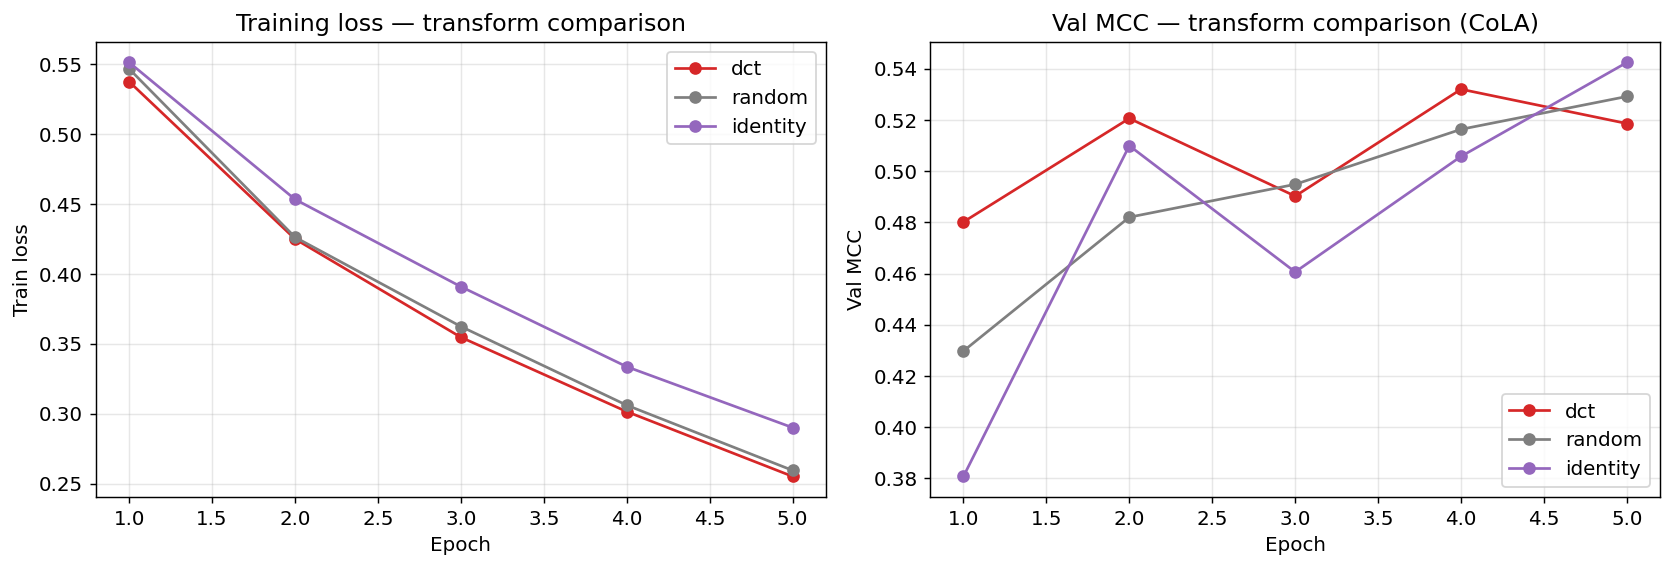

In [9]:
# ── Learning curves ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

colors = {'dct': 'tab:red', 'random': 'tab:gray', 'identity': 'tab:purple'}
for name, run in runs.items():
    eps   = [h['epoch'] for h in run['history']]
    loss  = [h['loss']  for h in run['history']]
    score = [h['score'] for h in run['history']]
    c = colors[name]
    axes[0].plot(eps, loss,  color=c, marker='o', label=name)
    axes[1].plot(eps, score, color=c, marker='o', label=name)

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Train loss')
axes[0].set_title('Training loss — transform comparison')
axes[0].legend()
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel(f'Val {METRIC.upper()}')
axes[1].set_title(f'Val {METRIC.upper()} — transform comparison (CoLA)')
axes[1].legend()
plt.tight_layout()
plt.savefig('results/exp1_transform_curves.png', bbox_inches='tight', dpi=150)
plt.show()

### 2.3 Experiment 2 — Varying n_faces with DCT (compression vs performance)

In [10]:
# Reduce n_faces to compress the adapter. L=12; keeping fewer faces is like
# low-pass filtering the adapter update along the depth axis.

face_runs = {}
for n_f in (1, 2, 4, 6, 12):
    label = f'dct_f{n_f}'
    print(f'\n=== n_faces={n_f} ===')
    face_runs[n_f] = run_mtlora(transform='dct', rank=8, n_faces=n_f,
                                alpha=4.0, epochs=EPOCHS, lr=LR, label=label)


=== n_faces=1 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=1, transform=dct, init_from_weights=False). Trainable params: 12,288
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=1, transform=dct, init_from_weights=False). Trainable params: 12,288
[dct_f1] trainable: 616,706
  ep 1/5  loss=0.5776  val_mcc=0.2933  active_faces=[1, 1]
  ep 2/5  loss=0.4834  val_mcc=0.3553  active_faces=[1, 1]
  ep 3/5  loss=0.4532  val_mcc=0.4313  active_faces=[1, 1]
  ep 4/5  loss=0.4364  val_mcc=0.4682  active_faces=[1, 1]
  ep 5/5  loss=0.4218  val_mcc=0.4601  active_faces=[1, 1]

=== n_faces=2 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (6 outputs left out)

[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=6, transform=dct, init_from_weights=False). Trainable params: 73,728
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=6, transform=dct, init_from_weights=False). Trainable params: 73,728
[dct_f6] trainable: 739,586
  ep 1/5  loss=0.5303  val_mcc=0.4952  active_faces=[6, 6]
  ep 2/5  loss=0.4325  val_mcc=0.4836  active_faces=[6, 6]
  ep 3/5  loss=0.3750  val_mcc=0.4911  active_faces=[6, 6]
  ep 4/5  loss=0.3376  val_mcc=0.4914  active_faces=[6, 6]
  ep 5/5  loss=0.3099  val_mcc=0.5160  active_faces=[6, 6]

=== n_faces=12 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[dct_f12] trainable: 887,042
  ep 1/5  loss=0.5376  val_mcc=0.4802  active_faces=[12, 12]
  ep 2/5  loss=0.4250  val_mcc=0.5206  active_faces=[12, 12]
  ep 3/5  loss=0.3547  val_mcc=0.4903  active_faces=[12, 12]
  ep 4/5  loss=0.3015  val_mcc=0.5320  active_faces=[12, 12]
  ep 5/5  loss=0.2551  val_mcc=0.5186  active_faces=[12, 12]


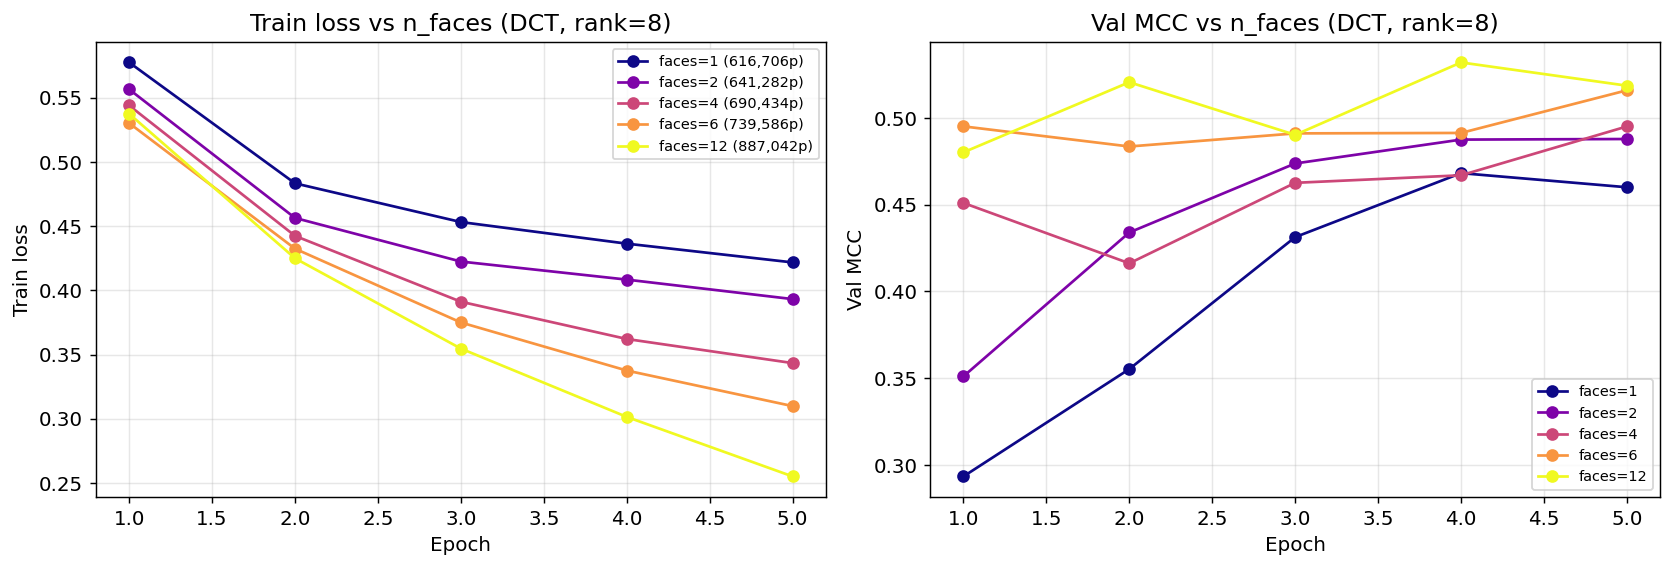


 n_faces     params    final MCC   params/LoRA-r8
       1    616,706       0.4601             2.09
       2    641,282       0.4879             2.17
       4    690,434       0.4951             2.34
       6    739,586       0.5160             2.51
      12    887,042       0.5186             3.01


In [11]:
# ── n_faces ablation plot ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cmap = plt.cm.get_cmap('plasma', len(face_runs))
for idx, (n_f, run) in enumerate(sorted(face_runs.items())):
    c  = cmap(idx)
    ep = [h['epoch'] for h in run['history']]
    axes[0].plot(ep, [h['loss']  for h in run['history']],
                 color=c, marker='o', label=f'faces={n_f} ({run["trainable"]:,}p)')
    axes[1].plot(ep, [h['score'] for h in run['history']],
                 color=c, marker='o', label=f'faces={n_f}')

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Train loss')
axes[0].set_title('Train loss vs n_faces (DCT, rank=8)')
axes[0].legend(fontsize=8)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel(f'Val {METRIC.upper()}')
axes[1].set_title(f'Val {METRIC.upper()} vs n_faces (DCT, rank=8)')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.savefig('results/exp2_nfaces_curves.png', bbox_inches='tight', dpi=150)
plt.show()

# ── Summary table ─────────────────────────────────────────────────────────────
print(f"\n{'n_faces':>8} {'params':>10} {'final MCC':>12} {'params/LoRA-r8':>16}")
lora_r8 = 12 * 8 * (768 + 768) * 2  # q+v adapters
for n_f, run in sorted(face_runs.items()):
    final = run['history'][-1]['score']
    print(f"{n_f:>8} {run['trainable']:>10,} {final:>12.4f} {run['trainable']/lora_r8:>16.2f}")

### 2.4 Experiment 3 — W₀-guided initialisation vs random

In [12]:
print('=== Random init ===')
r_rand = run_mtlora(transform='dct', rank=8, n_faces=4, alpha=4.0,
                    init_from_weights=False, epochs=EPOCHS, lr=LR, label='random_init')

print('\n=== W₀-guided init (tSVD-M of pretrained weights) ===')
r_w0   = run_mtlora(transform='dct', rank=8, n_faces=4, alpha=4.0,
                    init_from_weights=True, epochs=EPOCHS, lr=LR, label='W0_init')

=== Random init ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=4, transform=dct, init_from_weights=False). Trainable params: 49,152
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=4, transform=dct, init_from_weights=False). Trainable params: 49,152
[random_init] trainable: 690,434
  ep 1/5  loss=0.5441  val_mcc=0.4510  active_faces=[4, 4]
  ep 2/5  loss=0.4425  val_mcc=0.4162  active_faces=[4, 4]
  ep 3/5  loss=0.3912  val_mcc=0.4626  active_faces=[4, 4]
  ep 4/5  loss=0.3622  val_mcc=0.4670  active_faces=[4, 4]
  ep 5/5  loss=0.3434  val_mcc=0.4951  active_faces=[4, 4]

=== W₀-guided init (tSVD-M of pretrained weights) ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA] init_from_stacked: used top-4 faces of W0 tSVD-M (d_out=768, d_in=768, L=12, rank=8)
[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=4, transform=dct, init_from_weights=True). Trainable params: 49,152
[MTLoRA] init_from_stacked: used top-4 faces of W0 tSVD-M (d_out=768, d_in=768, L=12, rank=8)
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=4, transform=dct, init_from_weights=True). Trainable params: 49,152
[W0_init] trainable: 690,434
  ep 1/5  loss=0.5872  val_mcc=0.3037  active_faces=[4, 4]
  ep 2/5  loss=0.4564  val_mcc=0.4505  active_faces=[4, 4]
  ep 3/5  loss=0.4261  val_mcc=0.4942  active_faces=[4, 4]
  ep 4/5  loss=0.4039  val_mcc=0.5074  active_faces=[4, 4]
  ep 5/5  loss=0.3954  val_mcc=0.5180  active_faces=[4, 4]


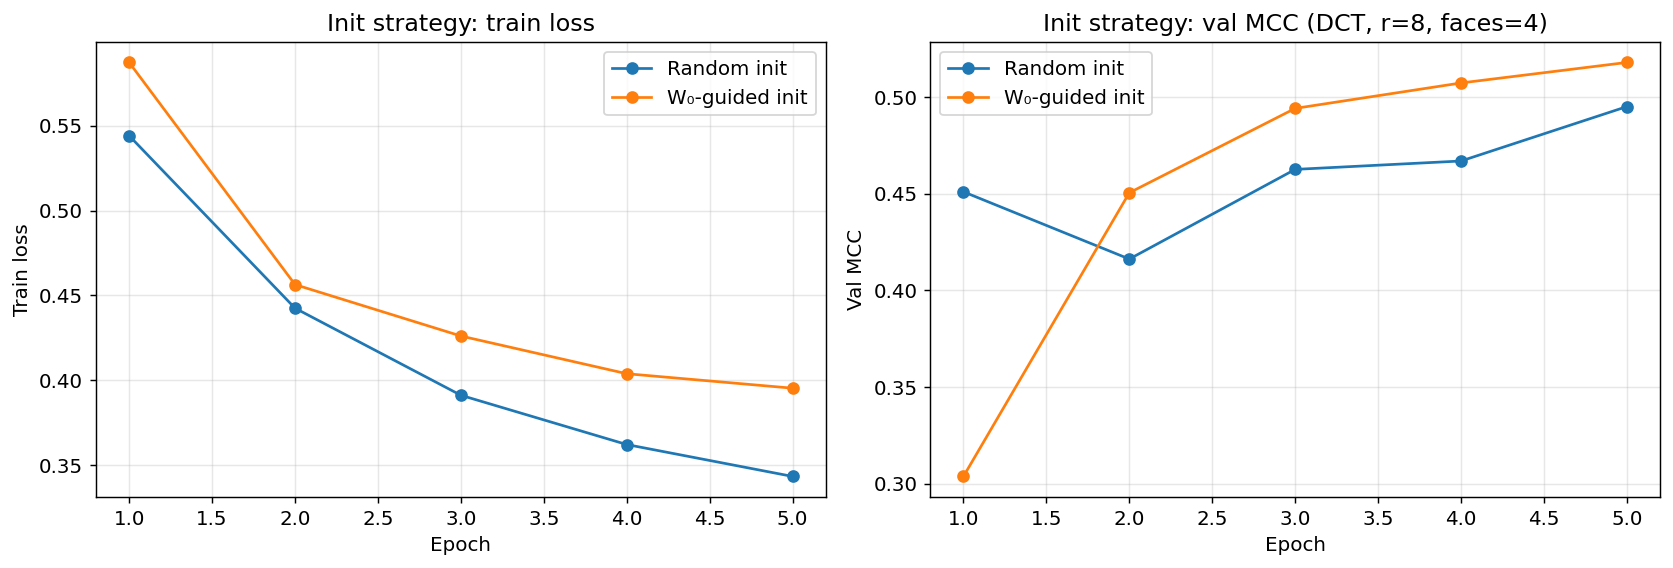

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for run, color, name in [(r_rand, 'tab:blue', 'Random init'),
                          (r_w0,   'tab:orange', 'W₀-guided init')]:
    ep    = [h['epoch'] for h in run['history']]
    axes[0].plot(ep, [h['loss']  for h in run['history']], color=color, marker='o', label=name)
    axes[1].plot(ep, [h['score'] for h in run['history']], color=color, marker='o', label=name)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Train loss')
axes[0].set_title('Init strategy: train loss')
axes[0].legend()
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel(f'Val {METRIC.upper()}')
axes[1].set_title(f'Init strategy: val {METRIC.upper()} (DCT, r=8, faces=4)')
axes[1].legend()
plt.tight_layout()
plt.savefig('results/exp3_init_comparison.png', bbox_inches='tight', dpi=150)
plt.show()

### 2.5 Experiment 4 — Dynamic rank pruning

In [16]:
print('=== No pruning ===')
r_no_prune = run_mtlora(transform='dct', rank=8, n_faces=12, alpha=4.0,
                        prune_threshold=0.0, epochs=EPOCHS, lr=LR, label='no_prune')

print('\n=== Pruning threshold=0.1 ===')
r_prune    = run_mtlora(transform='dct', rank=8, n_faces=12, alpha=4.0,
                        prune_threshold=0.1, epochs=EPOCHS, lr=LR, label='prune_0.1')

=== No pruning ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[no_prune] trainable: 887,042
  ep 1/5  loss=0.5376  val_mcc=0.4802  active_faces=[12, 12]
  ep 2/5  loss=0.4250  val_mcc=0.5206  active_faces=[12, 12]
  ep 3/5  loss=0.3547  val_mcc=0.4903  active_faces=[12, 12]
  ep 4/5  loss=0.3015  val_mcc=0.5320  active_faces=[12, 12]
  ep 5/5  loss=0.2551  val_mcc=0.5186  active_faces=[12, 12]

=== Pruning threshold=0.1 ===


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


[MTLoRA-fast] wrapped 12 'query' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[MTLoRA-fast] wrapped 12 'value' layers (rank=8, n_faces=12, transform=dct, init_from_weights=False). Trainable params: 147,456
[prune_0.1] trainable: 887,042
  ep 1/5  loss=0.5376  val_mcc=0.4802  active_faces=[12, 12]
  ep 2/5  loss=0.4250  val_mcc=0.5206  active_faces=[12, 12]
  ep 3/5  loss=0.3547  val_mcc=0.4903  active_faces=[12, 12]
  ep 4/5  loss=0.3015  val_mcc=0.5320  active_faces=[12, 12]
  ep 5/5  loss=0.2551  val_mcc=0.5186  active_faces=[12, 12]


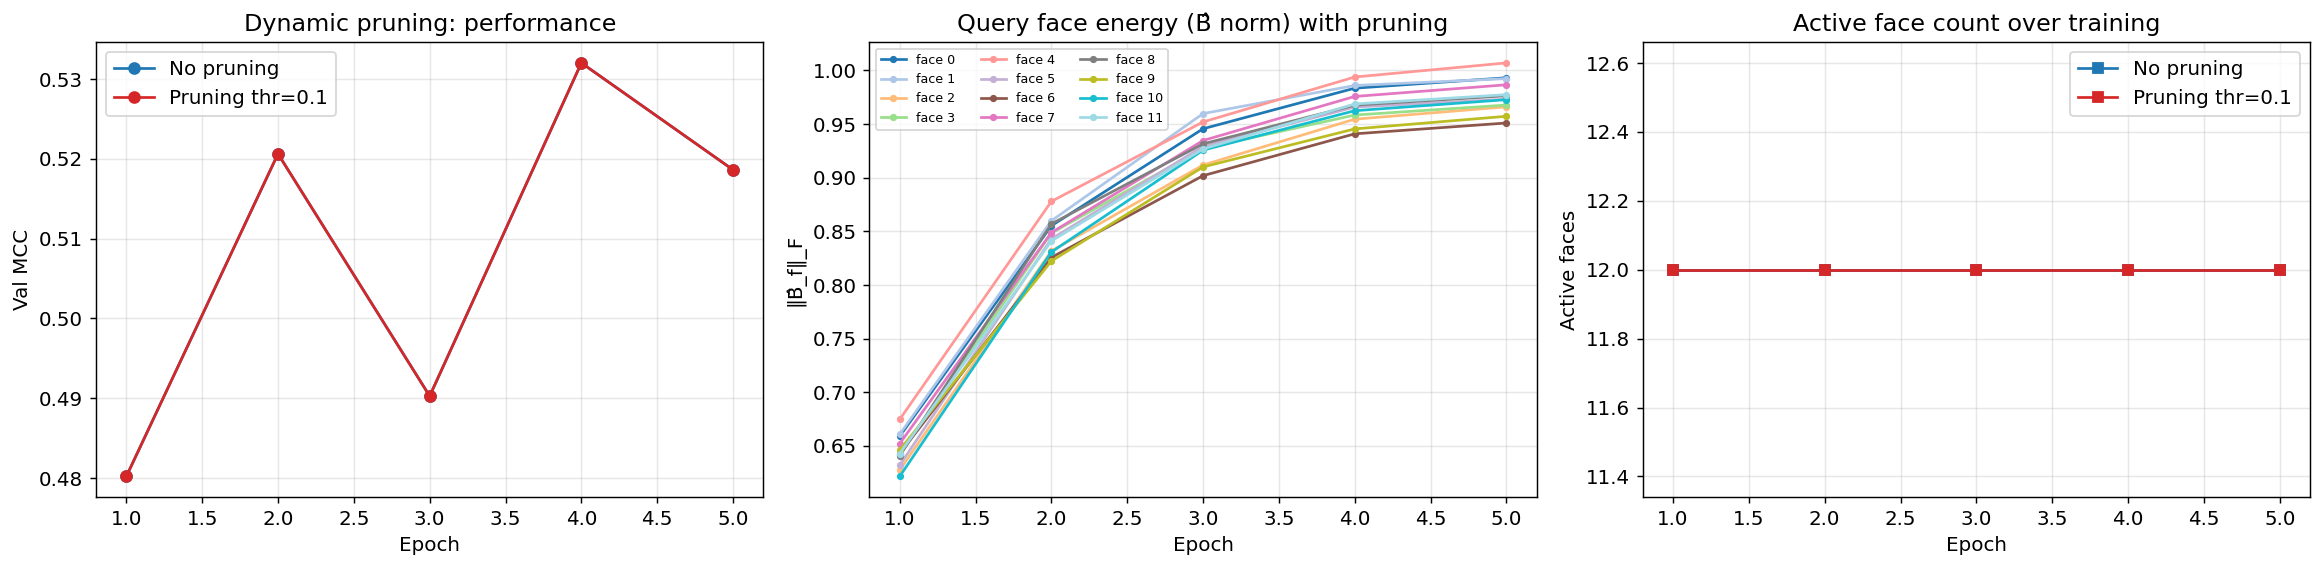

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# Learning curves
for run, c, name in [(r_no_prune, 'tab:blue', 'No pruning'),
                      (r_prune,    'tab:red',  'Pruning thr=0.1')]:
    ep = [h['epoch'] for h in run['history']]
    axes[0].plot(ep, [h['score'] for h in run['history']], color=c, marker='o', label=name)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel(f'Val {METRIC.upper()}')
axes[0].set_title('Dynamic pruning: performance'); axes[0].legend()

# Per-face energy over training for the query adapter (run with pruning)
ax = axes[1]
query_norms_by_epoch = [h['face_norms'][0] for h in r_prune['history']]
n_f = len(query_norms_by_epoch[0])
face_cmap = plt.cm.get_cmap('tab20', n_f)
for f in range(n_f):
    vals = [norms[f] for norms in query_norms_by_epoch]
    ax.plot(range(1, EPOCHS+1), vals, color=face_cmap(f), marker='.',
            label=f'face {f}')
ax.set_xlabel('Epoch'); ax.set_ylabel('‖B̂_f‖_F')
ax.set_title('Query face energy (B̂ norm) with pruning')
ax.legend(fontsize=7, ncol=3)

# Active face count over training
ax2 = axes[2]
for run, c, name in [(r_no_prune, 'tab:blue', 'No pruning'),
                      (r_prune,    'tab:red',  'Pruning thr=0.1')]:
    active = [run['adapters'][0].active_face_count()] * EPOCHS  # final state
    # For pruning, recover per-epoch state from history
    cum = [12] * EPOCHS
    pruned_so_far = 0
    for i, h in enumerate(run['history']):
        pruned_so_far += h['n_pruned']
        cum[i] = 12 - pruned_so_far
    ax2.plot(range(1, EPOCHS+1), cum, color=c, marker='s', label=name)
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Active faces')
ax2.set_title('Active face count over training')
ax2.legend()

plt.tight_layout()
plt.savefig('results/exp4_pruning.png', bbox_inches='tight', dpi=150)
plt.show()

---
## Phase 3 — Post-hoc analysis of a trained adapter
### 3.1 Load the pre-trained result from disk

In [18]:
# We use the run with n_faces=4, rank=8, DCT from Phase 2 (or load from file)
# If you just ran Exp 2, pick run with n_faces=4:
trained_run = face_runs.get(4, None)

if trained_run is None:
    # Re-train a quick version
    print('Re-training n_faces=4 adapter for post-hoc analysis...')
    trained_run = run_mtlora(transform='dct', rank=8, n_faces=4,
                             alpha=4.0, epochs=EPOCHS, lr=LR, label='posthoc')

adp_q = trained_run['adapters'][0]   # query adapter
adp_v = trained_run['adapters'][1]   # value adapter
print(f'query adapter: {adp_q}')
print(f'value adapter: {adp_v}')

query adapter: MTLoRA(d_out=768, d_in=768, L=12, rank=8, n_faces=4, alpha=4.0)
value adapter: MTLoRA(d_out=768, d_in=768, L=12, rank=8, n_faces=4, alpha=4.0)


### 3.2 Per-face singular value spectrum of the trained ΔŴ

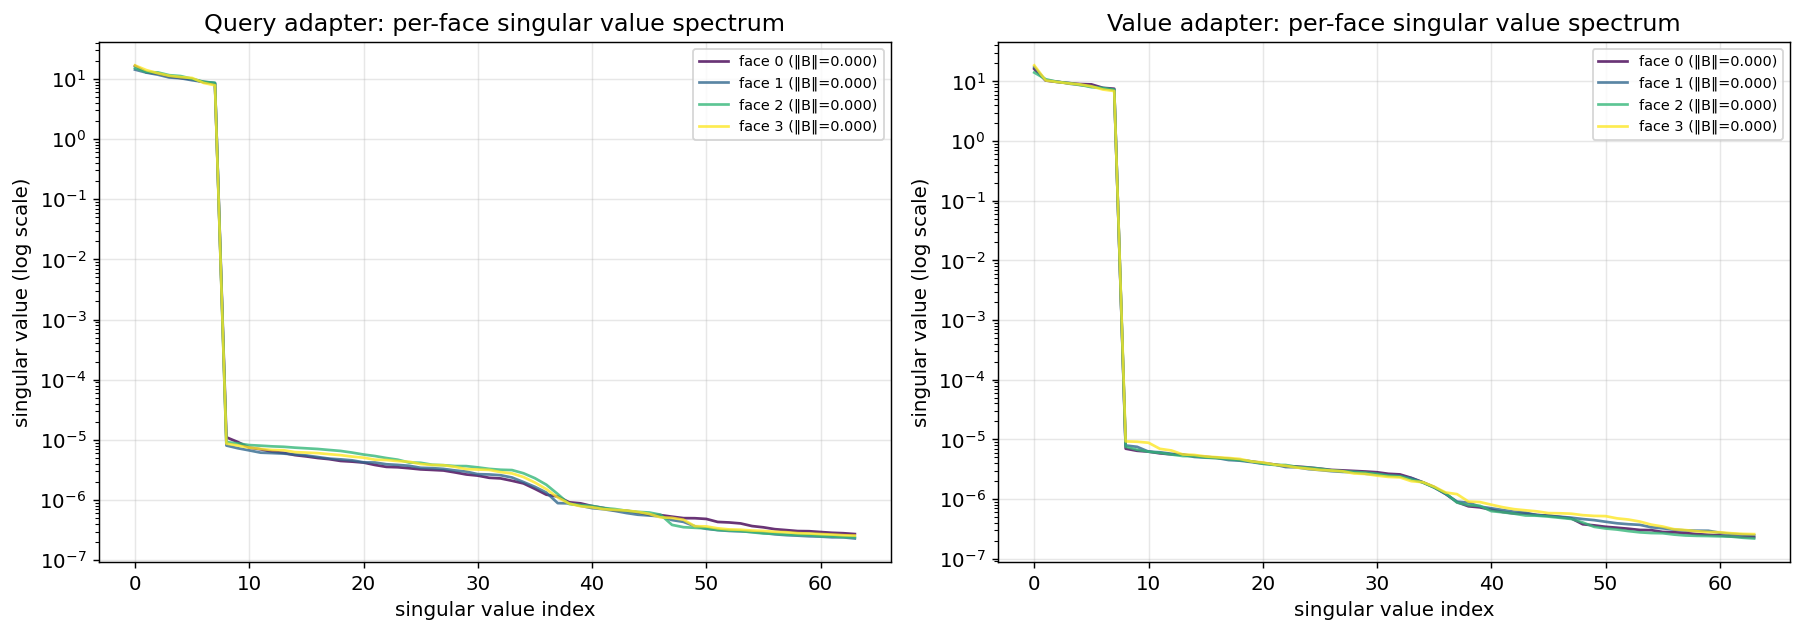

In [19]:
def face_singular_values(adapter):
    """Singular values of each transform-domain face of ΔŴ = facewise(Â, B̂)."""
    with torch.no_grad():
        dW_hat = adapter.compute_delta_hat().cpu()   # (d_out, d_in, p)
    svs = []
    for f in range(adapter.n_faces):
        sv = torch.linalg.svdvals(dW_hat[:, :, f]).numpy()
        svs.append(sv)
    return svs

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, adp, name in [(axes[0], adp_q, 'Query'), (axes[1], adp_v, 'Value')]:
    svs = face_singular_values(adp)
    cmap = plt.cm.get_cmap('viridis', adp.n_faces)
    for f, sv in enumerate(svs):
        ax.semilogy(sv[:64], color=cmap(f), alpha=0.8,
                    label=f'face {f} (‖B‖={adp.face_energy[f]:.3f})')
    ax.set_xlabel('singular value index')
    ax.set_ylabel('singular value (log scale)')
    ax.set_title(f'{name} adapter: per-face singular value spectrum')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('results/sv_spectrum.png', bbox_inches='tight', dpi=150)
plt.show()

### 3.3 ΔW subspace vs W₀ subspace — principal angle alignment

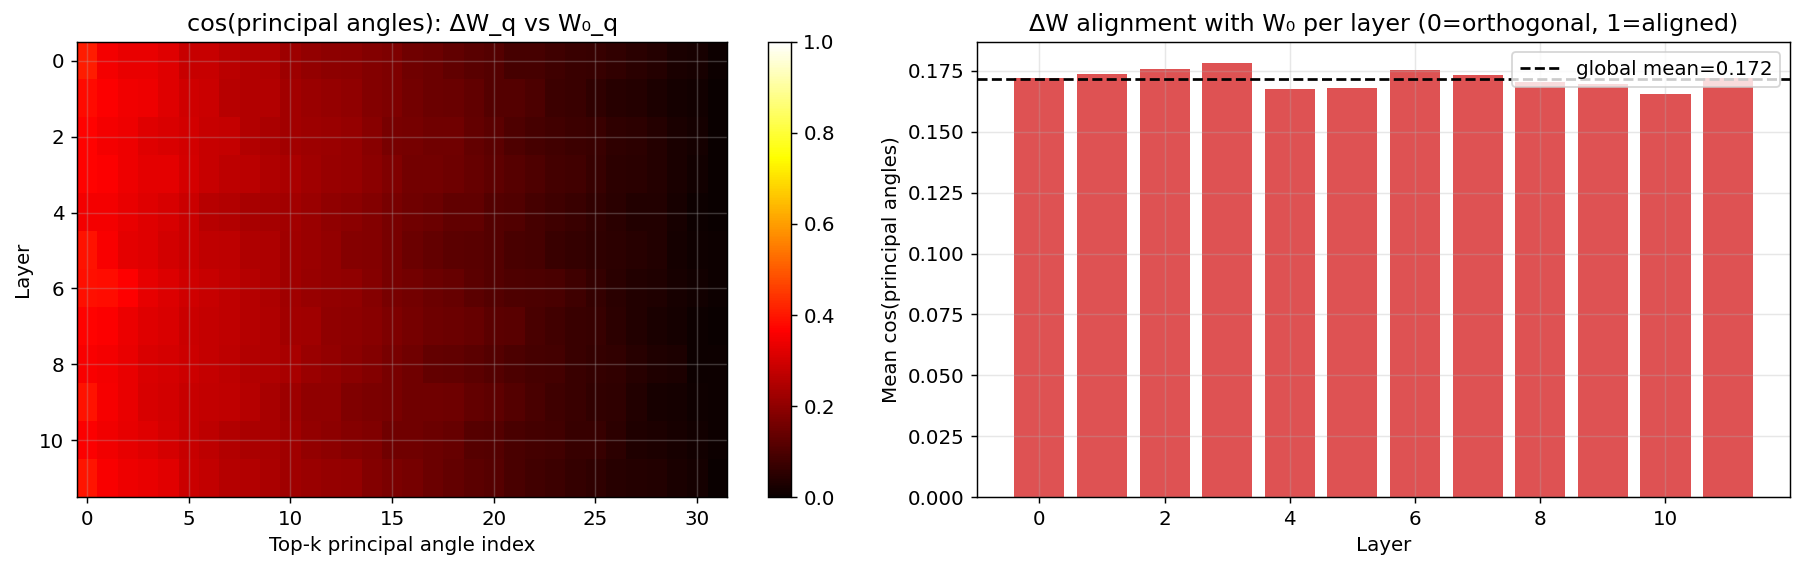


Global mean cosine(ΔW_q, W₀_q) = 0.1718  (0 = fully orthogonal; LoTR found ~0 → random init is better)


In [20]:
# Does the adapter update align with W₀'s top subspace or work orthogonally?
# (LoTR found adaptation is orthogonal to W₀, which motivates random over W₀ init.)

@torch.no_grad()
def subspace_alignment(adapter, W0_stacked, top_k=32):
    """Compute cosine of principal angles between top-k singular subspace of
       ΔW_ℓ and W₀_ℓ for every layer ℓ.
       Returns (L, top_k) array of cosines.
    """
    dW  = adapter.get_delta_W().float()              # (d_out, d_in, L)
    W0  = W0_stacked.to(dW.device).float()           # (d_out, d_in, L)
    L   = dW.shape[2]
    out = []
    for ell in range(L):
        Ud, _, _ = torch.linalg.svd(dW[:, :, ell], full_matrices=False)
        Uw, _, _ = torch.linalg.svd(W0[:, :, ell],  full_matrices=False)
        cos = torch.linalg.svdvals(Ud[:, :top_k].T @ Uw[:, :top_k])
        out.append(cos.cpu().numpy())
    return np.array(out)   # (L, top_k)

W0_q = torch.stack(
    [trained_run['model'].roberta.encoder.layer[i].attention.self.query.linear.weight.detach().cpu()
     for i in range(12)], dim=2
)

align = subspace_alignment(adp_q.cpu(), W0_q, top_k=32)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Heatmap: layer × singular index
im = axes[0].imshow(align, aspect='auto', cmap='hot', vmin=0, vmax=1)
axes[0].set_xlabel('Top-k principal angle index'); axes[0].set_ylabel('Layer')
axes[0].set_title('cos(principal angles): ΔW_q vs W₀_q')
plt.colorbar(im, ax=axes[0])

# Mean cosine per layer
axes[1].bar(range(12), align.mean(axis=1), color='tab:red', alpha=0.8)
axes[1].axhline(align.mean(), color='k', linestyle='--', label=f'global mean={align.mean():.3f}')
axes[1].set_xlabel('Layer'); axes[1].set_ylabel('Mean cos(principal angles)')
axes[1].set_title('ΔW alignment with W₀ per layer (0=orthogonal, 1=aligned)')
axes[1].legend()

plt.tight_layout()
plt.savefig('results/subspace_alignment.png', bbox_inches='tight', dpi=150)
plt.show()
print(f'\nGlobal mean cosine(ΔW_q, W₀_q) = {align.mean():.4f}'
      f'  (0 = fully orthogonal; LoTR found ~0 → random init is better)')

### 3.4 Parameter efficiency — final score vs trainable params for all runs

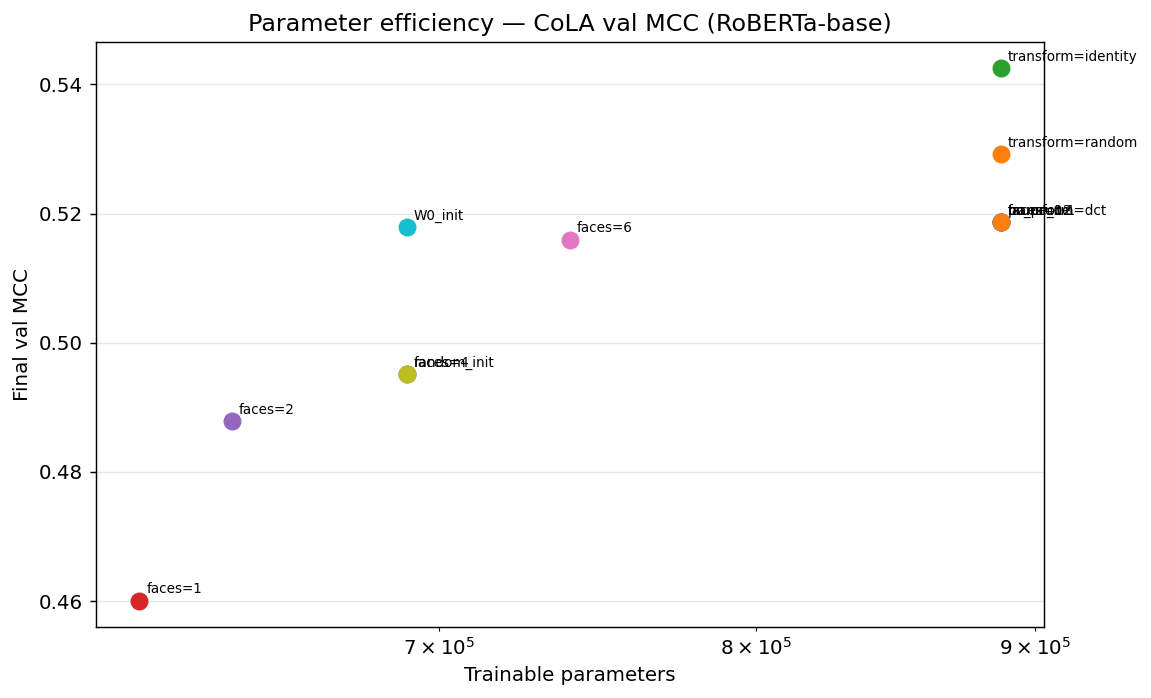


Run                            Params    Final MCC
--------------------------------------------------
transform=identity            887,042       0.5425
transform=random              887,042       0.5292
transform=dct                 887,042       0.5186
faces=12                      887,042       0.5186
no_prune                      887,042       0.5186
prune_0.1                     887,042       0.5186
W0_init                       690,434       0.5180
faces=6                       739,586       0.5160
faces=4                       690,434       0.4951
random_init                   690,434       0.4951
faces=2                       641,282       0.4879
faces=1                       616,706       0.4601


In [21]:
# Collect all runs that were created in this session
all_runs = {
    **{f'transform={k}': v for k, v in runs.items()},
    **{f'faces={k}': v      for k, v in face_runs.items()},
    'random_init': r_rand,
    'W0_init':     r_w0,
    'no_prune':    r_no_prune,
    'prune_0.1':   r_prune,
}

fig, ax = plt.subplots(figsize=(9, 5.5))

for name, run in all_runs.items():
    final = run['history'][-1]['score']
    ax.scatter(run['trainable'], final, s=80, zorder=5)
    ax.annotate(name, (run['trainable'], final),
                textcoords='offset points', xytext=(4, 4), fontsize=7.5)

ax.set_xscale('log')
ax.set_xlabel('Trainable parameters'); ax.set_ylabel(f'Final val {METRIC.upper()}')
ax.set_title(f'Parameter efficiency — CoLA val {METRIC.upper()} (RoBERTa-base)')
plt.tight_layout()
plt.savefig('results/param_efficiency.png', bbox_inches='tight', dpi=150)
plt.show()

# Text table
print(f"\n{'Run':<26} {'Params':>10} {'Final MCC':>12}")
print('-' * 50)
for name, run in sorted(all_runs.items(), key=lambda x: -x[1]['history'][-1]['score']):
    print(f"{name:<26} {run['trainable']:>10,} {run['history'][-1]['score']:>12.4f}")

### 3.5 Per-layer ΔW norms — does depth smoothness improve with DCT?

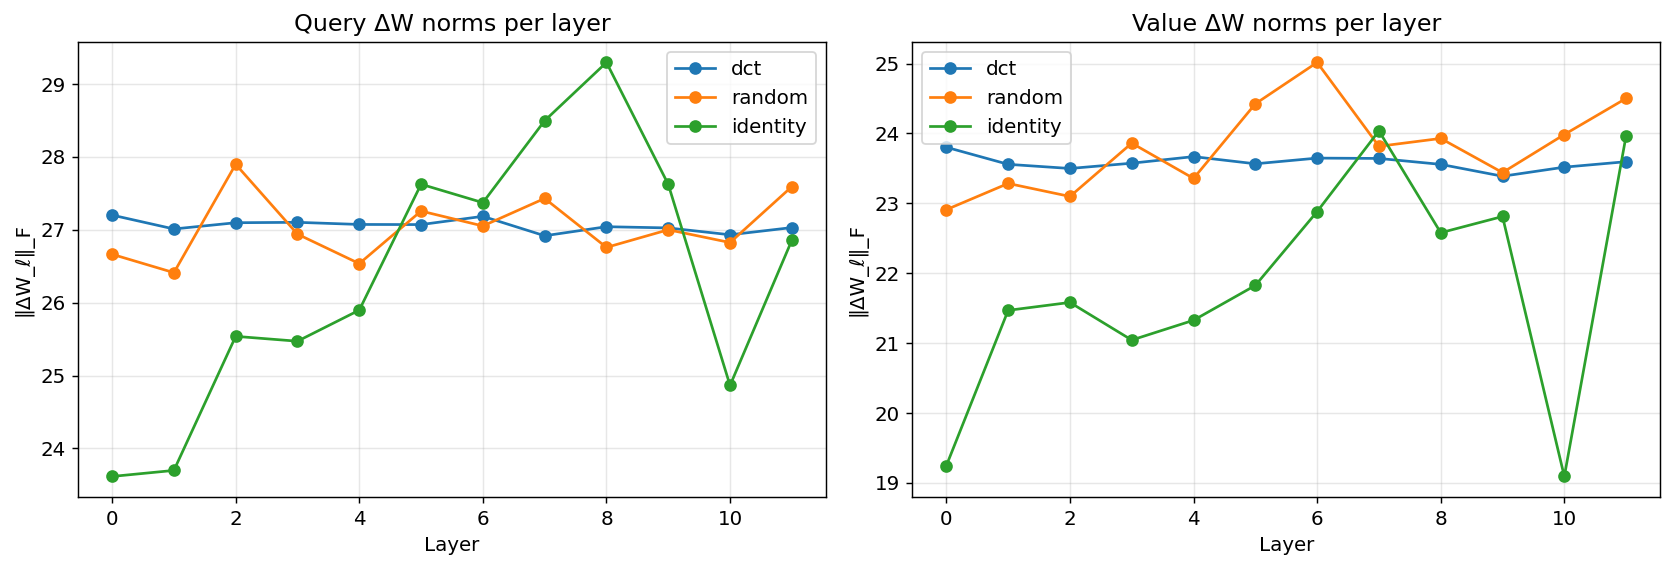


transform      query std/mean   value std/mean
dct                    0.0030           0.0041
random                 0.0157           0.0251
identity               0.0658           0.0691


In [22]:
@torch.no_grad()
def layer_delta_norms(adapter):
    dW = adapter.get_delta_W().float()   # (d_out, d_in, L)
    return [float(dW[:, :, l].norm('fro')) for l in range(dW.shape[2])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for ax, adp_key, title in [
    (axes[0], 'query', 'Query ΔW norms per layer'),
    (axes[1], 'value', 'Value ΔW norms per layer'),
]:
    for tfm, run in runs.items():
        idx = 0 if adp_key == 'query' else 1
        norms = layer_delta_norms(run['adapters'][idx].cpu())
        ax.plot(norms, marker='o', label=tfm)
    ax.set_xlabel('Layer'); ax.set_ylabel('‖ΔW_ℓ‖_F')
    ax.set_title(title); ax.legend()

plt.tight_layout()
plt.savefig('results/layer_norms.png', bbox_inches='tight', dpi=150)
plt.show()

# Compare smoothness (std/mean ratio)
print(f"\n{'transform':<12} {'query std/mean':>16} {'value std/mean':>16}")
for tfm, run in runs.items():
    for adp_k, idx in [('query', 0), ('value', 1)]:
        n = layer_delta_norms(run['adapters'][idx].cpu())
    nq = layer_delta_norms(run['adapters'][0].cpu())
    nv = layer_delta_norms(run['adapters'][1].cpu())
    print(f"{tfm:<12} {np.std(nq)/np.mean(nq):>16.4f} {np.std(nv)/np.mean(nv):>16.4f}")

---
## Summary

### Reading the results

| Question | Where to look | What a positive result looks like |
|---|---|---|
| Does DCT give better compression of ΔW? | Phase 1 Pareto curves | `tsvd_dct_*` Pareto frontier sits left of `tsvd_rand_*` and Tucker |
| Does the transform matter at all for fine-tuning? | Exp 1 curves | DCT or random clearly above identity on val MCC |
| Does keeping fewer faces hurt performance? | Exp 2 table | Small n_faces (e.g. 4) matches large n_faces with fewer params |
| Does W₀-guided init help? | Exp 3 curves | W₀-init converges faster or reaches higher MCC |
| Is dynamic pruning useful? | Exp 4 face-energy plot | Some faces converge to zero; pruning them does not hurt MCC |
| Is adaptation orthogonal to W₀? | Phase 3.3 cosine | Mean cosine close to 0 → orthogonal → random init preferred |

### Novel contribution summary

MTLoRA introduces three things not found in LoTR (Tucker2), FLoRA or TensLoRA:
1. **Any invertible M** — not just Tucker/CP/TT, but any orthogonal basis (DCT, learned Stiefel manifold).
2. **Low-frequency truncation** — keep only p ≤ L faces, not the full depth; this is not possible in Tucker2 without losing the cross-layer sharing.
3. **Per-face energy tracking and dynamic rank pruning** — the t-SVD-M provides a unique ordered depth spectrum, enabling face-level AdaLoRA without the rank-collapse problem Tucker has.

### Recommended next steps
```python
# 1. Run on MRPC, RTE, SST-2 to confirm across tasks
# 2. Implement learnable M via Cayley map (Stiefel manifold gradient)
# 3. Benchmark against LoTR and LoRTA at equal parameter budget on GLUE
# 4. Scale to a larger model (Llama-3-8B) for the more layers case where MTLoRA's
#    depth-sharing advantage is most pronounced
```